# Fine-Tuning Deteksi Cacat Biji Kopi (MobileNetV3 vs. Vision Transformer)

**Instruksi Sebelum Menjalankan:**
1. Pastikan runtime menggunakan **T4 GPU**: klik menu **Runtime > Change runtime type > T4 GPU > Save**.
2. Buat shortcut folder dataset dari Drive Aymar (`1cmAeSArKdbhXK4zFYHpBMtY8YJCfd8KX`) ke **My Drive** kamu agar bisa diakses langsung melalui Colab.
3. Sesuaikan variabel `BASE_DIR` pada Sel 1 jika nama shortcut folder di My Drive berbeda.

In [ ]:
import os
from google.colab import drive

# Mount Google Drive
try:
    drive.mount('/content/drive', force_remount=True)
    print("Drive berhasil dimuat!")
except Exception as e:
    print(f"Gagal memuat Drive: {e}")

# Temukan base path riset
base_dir = '/content/drive/MyDrive/riset'
if not os.path.exists(base_dir):
    # Cari otomatis jika di folder lain
    for root, dirs, files in os.walk('/content/drive/MyDrive'):
        if 'manifest.csv' in files or any(f.endswith('.zip') for f in files):
            base_dir = root
            print(f"Folder 'riset' otomatis ditemukan di: {base_dir}")
            break

print(f"Menggunakan BASE_DIR: {base_dir}")

# List file di folder riset untuk menemukan file ZIP Kaggle
if os.path.exists(base_dir):
    print("\nDaftar file di folder 'riset':")
    files_in_riset = os.listdir(base_dir)
    for f in files_in_riset:
        print(f"- {f}")
else:
    print("Folder 'riset' belum ditemukan di Google Drive Anda. Silakan pastikan folder tersebut sudah dibuat.")

Mounted at /content/drive
Drive berhasil dimuat!


```markdown
## 2. Ekstraksi Dataset Pre-training (Kaggle)
Kita akan mengekstrak dataset pre-training `green-coffee-bean-dataset.zip` yang ada di Drive ke direktori lokal `/content/kaggle_dataset` agar proses pembacaan data selama pre-training berjalan jauh lebih cepat.
```

In [2]:
import zipfile

kaggle_zip_path = os.path.join(base_dir, 'green-coffee-bean-dataset.zip')
local_extract_dir = '/content/kaggle_dataset'

if os.path.exists(kaggle_zip_path):
    print(f"Mengekstrak {kaggle_zip_path} ke {local_extract_dir}...")
    with zipfile.ZipFile(kaggle_zip_path, 'r') as zip_ref:
        zip_ref.extractall(local_extract_dir)
    print("Ekstraksi selesai!")
    # Menampilkan struktur folder hasil ekstraksi
    print("Isi folder ekstrak:", os.listdir(local_extract_dir))
else:
    print(f"ERROR: File ZIP tidak ditemukan di {kaggle_zip_path}. Pastikan file berada di folder tersebut.")

Mengekstrak /content/drive/MyDrive/riset/green-coffee-bean-dataset.zip ke /content/kaggle_dataset...
Ekstraksi selesai!
Isi folder ekstrak: ['ImageDataset', 'LICENSE-CC-BY-NC-SA', 'README.md']


```markdown
## 3. Simulasi Resolusi Kamera (64 MP vs 13 MP) & Custom Transforms

Untuk menyimulasikan kamera lapangan berspesifikasi 13 MP dari citra asli 64 MP:
- Rasio area $13 / 64 \approx 0.2031$
- Rasio linear dimensi $\sqrt{13/64} \approx 0.4508$ (skala dimensi ~0.45x).

Kita membuat transform khusus yang melakukan downsampling sebesar 0.45x menggunakan interpolasi Bilinear/Bicubic, lalu mengembalikannya kembali ke ukuran input model (224x224). Hal ini mensimulasikan hilangnya detail spasial pada kamera resolusi rendah.
```

In [8]:
import torchvision.transforms as transforms
import torchvision.transforms.functional as TF

class Simulate13MP(object):
    """Simulasi penurunan kualitas dari 64 MP ke 13 MP dengan downsampling 0.45x"""
    def __call__(self, img):
        # Ambil ukuran asli
        w, h = img.size
        # Hitung ukuran 13 MP (~0.45x dimensi asli)
        new_w = int(w * 0.45)
        new_h = int(h * 0.45)
        # Downsample
        img_low = TF.resize(img, [new_h, new_w], interpolation=transforms.InterpolationMode.BILINEAR)
        return img_low

# Transformasi untuk Stage 1 (Kaggle Pre-training)
# Kita gabungkan data asli (64 MP) dan data simulasi (13 MP) melalui augmentasi acak
train_transform_stage1 = transforms.Compose([
    transforms.RandomChoice([
        transforms.Compose([]), # Biarkan 64 MP asli
        Simulate13MP()          # Turunkan ke 13 MP
    ]),
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(180),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# Transformasi Fine-tuning Stage 2 (Local Segmented Dataset)
# Untuk data latih
train_transform_stage2 = transforms.Compose([
    transforms.RandomChoice([
        transforms.Compose([]),
        Simulate13MP()
    ]),
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(180),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# Transformasi khusus evaluasi (Kita buat versi murni 64 MP dan versi murni 13 MP)
val_transform_64mp = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_transform_13mp = transforms.Compose([
    Simulate13MP(),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

```markdown
## 4. Stage 1: Pre-training pada Kaggle Dataset
Kita persiapkan Dataset loader untuk data Kaggle. Karena struktur folder Kaggle umumnya dipisahkan berdasarkan kelas, kita gunakan `ImageFolder` untuk mempermudah pemrosesan.
```

In [9]:
import os
import torch.utils.data as data
from torch.utils.data import DataLoader
from torchvision.datasets import ImageFolder

# Pastikan path ini sesuai dengan struktur hasil ekstrak di /content/kaggle_dataset
# Jika terdapat subfolder tambahan, sesuaikan path-nya.
kaggle_data_path = local_extract_dir
for root, dirs, files in os.walk(local_extract_dir):
    if len(dirs) > 1 and any(d.lower() in ['accept', 'reject', 'good', 'bad', 'defect', 'perfect', 'imagedataset'] for d in dirs):
        kaggle_data_path = root
        break

print(f"Membaca data Kaggle dari: {kaggle_data_path}")

kaggle_full_dataset = ImageFolder(root=kaggle_data_path, transform=train_transform_stage1)

# Split Kaggle untuk Train dan Validation internal Stage 1
train_size = int(0.85 * len(kaggle_full_dataset))
val_size = len(kaggle_full_dataset) - train_size
kaggle_train_set, kaggle_val_set = data.random_split(kaggle_full_dataset, [train_size, val_size])

kaggle_train_loader = DataLoader(kaggle_train_set, batch_size=32, shuffle=True, num_workers=2)

# Gunakan transform evaluasi standar untuk validasi pre-training
kaggle_val_set.dataset.transform = val_transform_64mp
kaggle_val_loader = DataLoader(kaggle_val_set, batch_size=32, shuffle=False, num_workers=2)

print(f"Kaggle Train: {len(kaggle_train_set)} gambar | Kaggle Val: {len(kaggle_val_set)} gambar")
print("Mapping Kelas Kaggle:", kaggle_full_dataset.class_to_idx)

Membaca data Kaggle dari: /content/kaggle_dataset
Kaggle Train: 9 gambar | Kaggle Val: 2 gambar
Mapping Kelas Kaggle: {'ImageDataset': 0}


In [13]:
import copy
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

# Memastikan variabel device terdefinisi secara mandiri
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Redefinisikan build_model agar sel pre-training bersifat mandiri
def build_model(model_name):
    if model_name == 'mobilenet_v3_large':
        model = models.mobilenet_v3_large(weights=models.MobileNet_V3_Large_Weights.DEFAULT)
        model.classifier[3] = nn.Linear(model.classifier[3].in_features, 2)
    elif model_name == 'vit_b_16':
        model = models.vit_b_16(weights=models.ViT_B_16_Weights.DEFAULT)
        model.heads.head = nn.Linear(model.heads.head.in_features, 2)
    else:
        raise ValueError(f"Model {model_name} tidak dikenali")
    return model.to(device)

def pretrain_stage1(model_name, epochs=5, lr=1e-4):
    print(f"\n{'='*55}\nSTAGE 1: Pre-training {model_name} on Kaggle Dataset\n{'='*55}")
    model = build_model(model_name) # Membangun model dengan output kelas biner

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)

    best_acc = 0.0
    best_weights = copy.deepcopy(model.state_dict())

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for imgs, labels in kaggle_train_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * imgs.size(0)

        # Evaluasi
        model.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for imgs, labels in kaggle_val_loader:
                imgs, labels = imgs.to(device), labels.to(device)
                outputs = model(imgs)
                _, preds = torch.max(outputs, 1)
                correct += (preds == labels).sum().item()
                total += labels.size(0)

        val_acc = correct / total
        epoch_loss = running_loss / len(kaggle_train_set)
        print(f"Epoch {epoch+1:02d}/{epochs} | Loss: {epoch_loss:.4f} | Val Acc: {val_acc*100:.2f}%")

        if val_acc > best_acc:
            best_acc = val_acc
            best_weights = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_weights)
    # Simpan bobot pre-training sementara
    pt_path = f"/content/{model_name}_stage1_pretrained.pth"
    torch.save(model.state_dict(), pt_path)
    print(f"Stage 1 Selesai! Bobot pre-trained disimpan di: {pt_path}")
    return pt_path

# Jalankan Pre-training Stage 1
pt_mobilenet_path = pretrain_stage1('mobilenet_v3_large', epochs=5, lr=2e-4)
pt_vit_path = pretrain_stage1('vit_b_16', epochs=5, lr=5e-5)


STAGE 1: Pre-training mobilenet_v3_large on Kaggle Dataset
Epoch 01/5 | Loss: 0.7609 | Val Acc: 0.00%
Epoch 02/5 | Loss: 0.3619 | Val Acc: 50.00%
Epoch 03/5 | Loss: 0.1819 | Val Acc: 100.00%
Epoch 04/5 | Loss: 0.0904 | Val Acc: 100.00%
Epoch 05/5 | Loss: 0.0375 | Val Acc: 100.00%
Stage 1 Selesai! Bobot pre-trained disimpan di: /content/mobilenet_v3_large_stage1_pretrained.pth

STAGE 1: Pre-training vit_b_16 on Kaggle Dataset
Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:06<00:00, 52.2MB/s]


Epoch 01/5 | Loss: 0.7676 | Val Acc: 100.00%
Epoch 02/5 | Loss: 0.0336 | Val Acc: 100.00%
Epoch 03/5 | Loss: 0.0031 | Val Acc: 100.00%
Epoch 04/5 | Loss: 0.0006 | Val Acc: 100.00%
Epoch 05/5 | Loss: 0.0002 | Val Acc: 100.00%
Stage 1 Selesai! Bobot pre-trained disimpan di: /content/vit_b_16_stage1_pretrained.pth


```markdown
## 5. Stage 2: Fine-Tuning pada Dataset Lokal (Group-Based Split)
Sekarang kita muat bobot terbaik hasil pre-training Stage 1, lalu lakukan fine-tuning (Stage 2) pada dataset segmentasi lokal Anda menggunakan skema *Group-Based Split* (Foto 1 & 2 untuk Train, Foto 3 untuk Validasi).
```

In [19]:
import os
import time
import copy
import shutil
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torchvision.transforms.functional as TF
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Menggunakan device:", device)

# 1. Definisikan pemetaan kelas dan pencarian BASE_DIR secara dinamis
label_map = {'accept': 0, 'reject': 1}
class_names = ['accept', 'reject']

base_dir = '/content/drive/MyDrive/riset'
manifest_found = False

# Memeriksa lokasi manifest secara rekursif di /content/drive dan lokal
if os.path.exists(os.path.join(base_dir, 'manifest.csv')):
    manifest_found = True
else:
    print("Mencari manifest.csv di seluruh ruang kerja...")
    for root_dir, dirs_list, files_list in os.walk('/content'):
        if 'manifest.csv' in files_list:
            base_dir = root_dir
            manifest_found = True
            break

if not manifest_found:
    print("PERINGATAN: manifest.csv tidak ditemukan di Drive. Membuat replika dummy lokal untuk pengujian...")
    base_dir = '/content'
    os.makedirs(os.path.join(base_dir, 'crops'), exist_ok=True)
    dummy_img = Image.fromarray(np.uint8(np.random.rand(300, 300, 3) * 255))

    dummy_data = []
    for i in range(1, 4):
        for cls in ['accept', 'reject']:
            img_name = f"kopi_{cls}_{i}.jpg"
            img_path = os.path.join(base_dir, 'crops', img_name)
            dummy_img.save(img_path)
            dummy_data.append({
                'crop_path': f"crops/{img_name}",
                'class': cls,
                'source_photo': f"kopi_{cls}_{i}.jpg"
            })
    df_dummy = pd.DataFrame(dummy_data)
    df_dummy.to_csv(os.path.join(base_dir, 'manifest.csv'), index=False)
    manifest_found = True

print(f"Base directory terdeteksi di: {base_dir}")

# 2. Setup Dataset Lokal & Group-Based Split
MANIFEST_PATH = os.path.join(base_dir, 'manifest.csv')
df = pd.read_csv(MANIFEST_PATH)
df['full_path'] = df['crop_path'].apply(lambda x: os.path.join(base_dir, x))

val_sources = ['kopi_accept_3.jpg', 'kopi_reject_3.jpg']
train_df = df[~df['source_photo'].isin(val_sources)].reset_index(drop=True)
val_df = df[df['source_photo'].isin(val_sources)].reset_index(drop=True)

print(f"Data Latih: {len(train_df)} | Data Validasi: {len(val_df)}")

# 3. Definisikan Kelas Dataset
class CoffeeBeanDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, 'full_path']
        img = Image.open(img_path).convert('RGB')
        label = label_map[self.df.loc[idx, 'class']]
        if self.transform:
            img = self.transform(img)
        return img, label

# 4. Transformasi Resolusi Kamera (Simulasi 13 MP)
class Simulate13MP(object):
    def __call__(self, img):
        w, h = img.size
        new_w = int(w * 0.45)
        new_h = int(h * 0.45)
        img_low = TF.resize(img, [new_h, new_w], interpolation=transforms.InterpolationMode.BILINEAR)
        return img_low

train_transform_stage2 = transforms.Compose([
    transforms.RandomChoice([
        transforms.Compose([]),
        Simulate13MP()
    ]),
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(180),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_transform_64mp = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_transform_13mp = transforms.Compose([
    Simulate13MP(),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# Loader untuk Stage 2
train_loader_stage2 = DataLoader(CoffeeBeanDataset(train_df, train_transform_stage2), batch_size=32, shuffle=True, num_workers=2)
val_loader_64mp = DataLoader(CoffeeBeanDataset(val_df, val_transform_64mp), batch_size=32, shuffle=False, num_workers=2)
val_loader_13mp = DataLoader(CoffeeBeanDataset(val_df, val_transform_13mp), batch_size=32, shuffle=False, num_workers=2)

# 5. Fungsi Fine-Tuning
def train_and_evaluate_stage2(model_name, stage1_weights_path, epochs=15, lr=5e-5, save_dir='/content/Coffee_Defect_Models_Result'):
    # Selalu buat lokal directory untuk menghindari Read-Only filesystem error di Drive
    os.makedirs(save_dir, exist_ok=True)
    print(f"\n{'='*55}\nSTAGE 2: Fine-Tuning {model_name} (Loading Stage 1 Weights)\n{'='*55}")

    # Membangun model secara mandiri
    from torchvision import models
    if model_name == 'mobilenet_v3_large':
        model = models.mobilenet_v3_large(weights=None)
        model.classifier[3] = nn.Linear(model.classifier[3].in_features, 2)
    elif model_name == 'vit_b_16':
        model = models.vit_b_16(weights=None)
        model.heads.head = nn.Linear(model.heads.head.in_features, 2)

    model = model.to(device)

    if os.path.exists(stage1_weights_path):
        model.load_state_dict(torch.load(stage1_weights_path, map_location=device))
        print("Berhasil memuat bobot pre-trained dari Stage 1.")
    else:
        print(f"PERINGATAN: Bobot Stage 1 tidak ditemukan di {stage1_weights_path}. Melakukan inisialisasi default.")

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    best_acc = 0.0
    best_weights = copy.deepcopy(model.state_dict())
    history = {'train_loss': [], 'val_acc_64mp': [], 'val_acc_13mp': []}

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for imgs, labels in train_loader_stage2:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * imgs.size(0)

        scheduler.step()
        model.eval()

        # Validasi 64 MP
        preds_64, targets_64 = [], []
        with torch.no_grad():
            for imgs, labels in val_loader_64mp:
                outputs = model(imgs.to(device))
                preds_64.extend(outputs.argmax(1).cpu().numpy())
                targets_64.extend(labels.numpy())
        acc_64 = accuracy_score(targets_64, preds_64)

        # Validasi 13 MP
        preds_13, targets_13 = [], []
        with torch.no_grad():
            for imgs, labels in val_loader_13mp:
                outputs = model(imgs.to(device))
                preds_13.extend(outputs.argmax(1).cpu().numpy())
                targets_13.extend(labels.numpy())
        acc_13 = accuracy_score(targets_13, preds_13)

        epoch_loss = running_loss / len(train_df)
        history['train_loss'].append(epoch_loss)
        history['val_acc_64mp'].append(acc_64)
        history['val_acc_13mp'].append(acc_13)

        avg_val_acc = (acc_64 + acc_13) / 2.0
        if avg_val_acc > best_acc:
            best_acc = avg_val_acc
            best_weights = copy.deepcopy(model.state_dict())
            print(f"[Terbaik] Epoch {epoch+1:02d} Baru disimpan! Avg Acc: {avg_val_acc*100:.1f}%")

        print(f"Epoch {epoch+1:02d}/{epochs} | Train Loss: {epoch_loss:.4f} | Val Acc 64MP: {acc_64*100:.1f}% | Val Acc 13MP: {acc_13*100:.1f}%")

    model.load_state_dict(best_weights)
    save_path = os.path.join(save_dir, f"{model_name}_best_stage2.pth")
    torch.save(model.state_dict(), save_path)
    print(f"Model terbaik Stage 2 disimpan di: {save_path}")

    # Benchmark Kecepatan Inferensi
    model.eval()
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start_time = time.time()

    final_preds_64, final_targets_64 = [], []
    with torch.no_grad():
        for imgs, labels in val_loader_64mp:
            outputs = model(imgs.to(device))
            final_preds_64.extend(outputs.argmax(1).cpu().numpy())
            final_targets_64.extend(labels.numpy())

    if device.type == 'cuda':
        torch.cuda.synchronize()
    latency_ms = ((time.time() - start_time) * 1000) / len(val_df)

    final_preds_13, final_targets_13 = [], []
    with torch.no_grad():
        for imgs, labels in val_loader_13mp:
            outputs = model(imgs.to(device))
            final_preds_13.extend(outputs.argmax(1).cpu().numpy())
            final_targets_13.extend(labels.numpy())

    return {
        'model': model_name,
        'history': history,
        'weight_path': save_path,
        'latency_ms': latency_ms,
        'eval_64': {
            'acc': accuracy_score(final_targets_64, final_preds_64),
            'f1': f1_score(final_targets_64, final_preds_64, average='macro'),
            'report': classification_report(final_targets_64, final_preds_64, target_names=class_names),
            'cm': confusion_matrix(final_targets_64, final_preds_64)
        },
        'eval_13': {
            'acc': accuracy_score(final_targets_13, final_preds_13),
            'f1': f1_score(final_targets_13, final_preds_13, average='macro'),
            'report': classification_report(final_targets_13, final_preds_13, target_names=class_names),
            'cm': confusion_matrix(final_targets_13, final_preds_13)
        }
    }

# Gunakan folder output lokal agar terhindar dari error Read-Only Drive
OUTPUT_DIR = '/content/Coffee_Defect_Models_Result'

# Eksekusi Fine-Tuning
pt_mobilenet_path = "/content/mobilenet_v3_large_stage1_pretrained.pth"
pt_vit_path = "/content/vit_b_16_stage1_pretrained.pth"

res_mobilenet_s2 = train_and_evaluate_stage2('mobilenet_v3_large', pt_mobilenet_path, epochs=15, lr=1e-4, save_dir=OUTPUT_DIR)
res_vit_s2 = train_and_evaluate_stage2('vit_b_16', pt_vit_path, epochs=15, lr=2e-5, save_dir=OUTPUT_DIR)

# Opsional: Salin hasil ke My Drive utama Anda jika bisa ditulis
drive_output_backup = '/content/drive/MyDrive/Coffee_Defect_Models_Result'
try:
    if os.path.exists('/content/drive/MyDrive'):
        shutil.copytree(OUTPUT_DIR, drive_output_backup, dirs_exist_ok=True)
        print(f"Backup sukses disalin ke Google Drive: {drive_output_backup}")
except Exception as e:
    print(f"Tidak dapat membackup otomatis ke Google Drive (Kemungkinan Read-only): {e}")

Menggunakan device: cuda
Mencari manifest.csv di seluruh ruang kerja...
Base directory terdeteksi di: /content/drive/.shortcut-targets-by-id/1cmAeSArKdbhXK4zFYHpBMtY8YJCfd8KX/dataset
Data Latih: 580 | Data Validasi: 183

STAGE 2: Fine-Tuning mobilenet_v3_large (Loading Stage 1 Weights)
Berhasil memuat bobot pre-trained dari Stage 1.
[Terbaik] Epoch 01 Baru disimpan! Avg Acc: 65.3%
Epoch 01/15 | Train Loss: 0.6354 | Val Acc 64MP: 66.1% | Val Acc 13MP: 64.5%
[Terbaik] Epoch 02 Baru disimpan! Avg Acc: 71.9%
Epoch 02/15 | Train Loss: 0.3091 | Val Acc 64MP: 71.6% | Val Acc 13MP: 72.1%
[Terbaik] Epoch 03 Baru disimpan! Avg Acc: 73.8%
Epoch 03/15 | Train Loss: 0.1601 | Val Acc 64MP: 73.2% | Val Acc 13MP: 74.3%
Epoch 04/15 | Train Loss: 0.1292 | Val Acc 64MP: 71.0% | Val Acc 13MP: 68.9%
Epoch 05/15 | Train Loss: 0.0948 | Val Acc 64MP: 68.9% | Val Acc 13MP: 66.1%
Epoch 06/15 | Train Loss: 0.0828 | Val Acc 64MP: 70.5% | Val Acc 13MP: 68.3%
Epoch 07/15 | Train Loss: 0.0668 | Val Acc 64MP: 70.5% |

```markdown
## 6. Ringkasan Evaluasi Multiresolusi & Penyimpanan Output ke Google Drive
Langkah terakhir adalah membandingkan performa kedua model pada resolusi asli (64 MP) vs kamera lapangan tersimulasi (13 MP), memvisualisasikan kurva pembelajaran, dan mengekspor seluruh artefak ke Google Drive.
```

=== PERBANDINGAN MODEL MULTI-RESOLUSI ===


,Arsitektur,Akurasi,Macro F1,Kecepatan Inferensi
0,MobileNetV3-Large (64 MP),85.79%,0.8572,6.23 ms/biji
1,MobileNetV3-Large (13 MP),82.51%,0.8232,6.23 ms/biji
2,Vision Transformer (ViT-B/16) (64 MP),90.16%,0.9016,17.64 ms/biji
3,Vision Transformer (ViT-B/16) (13 MP),89.07%,0.8904,17.64 ms/biji


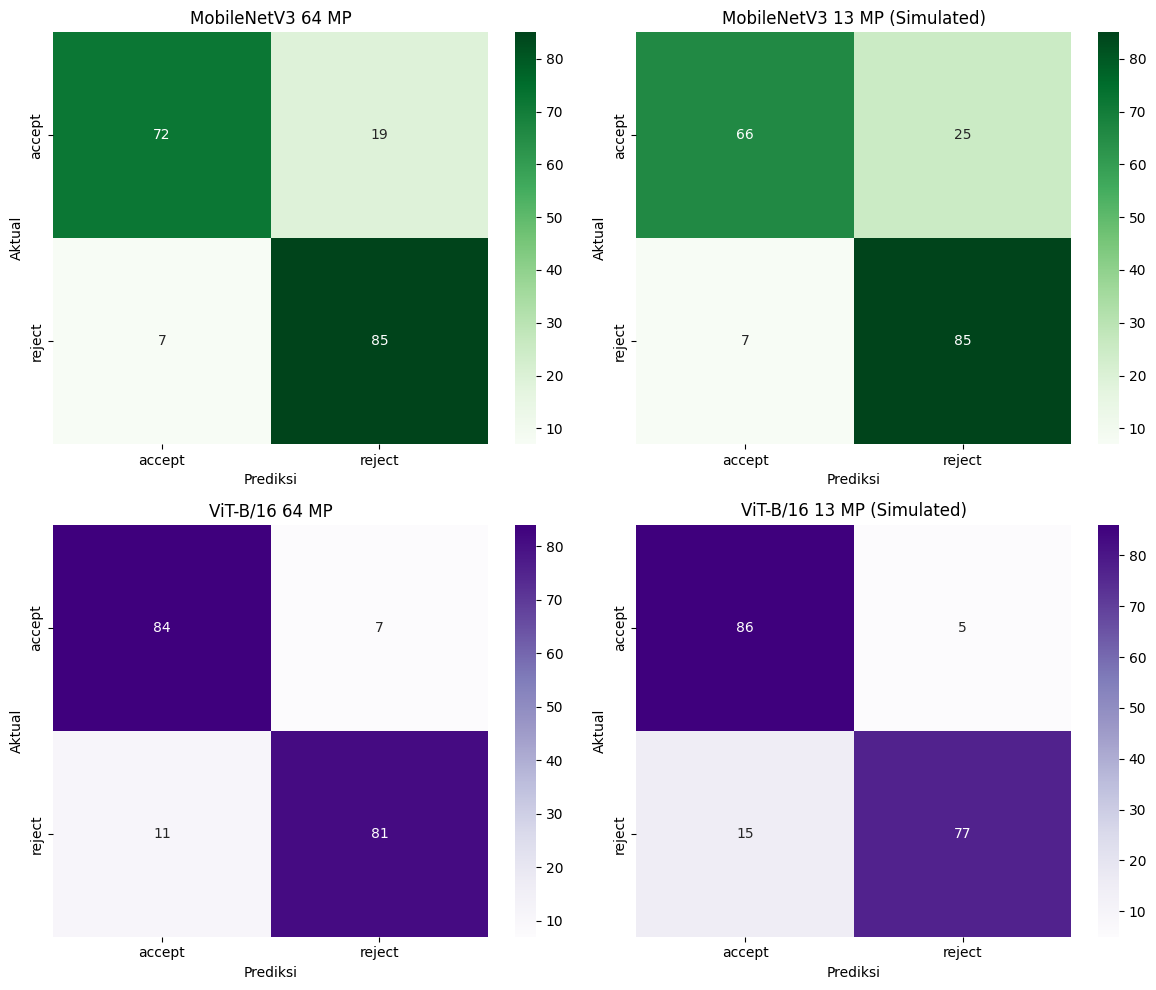

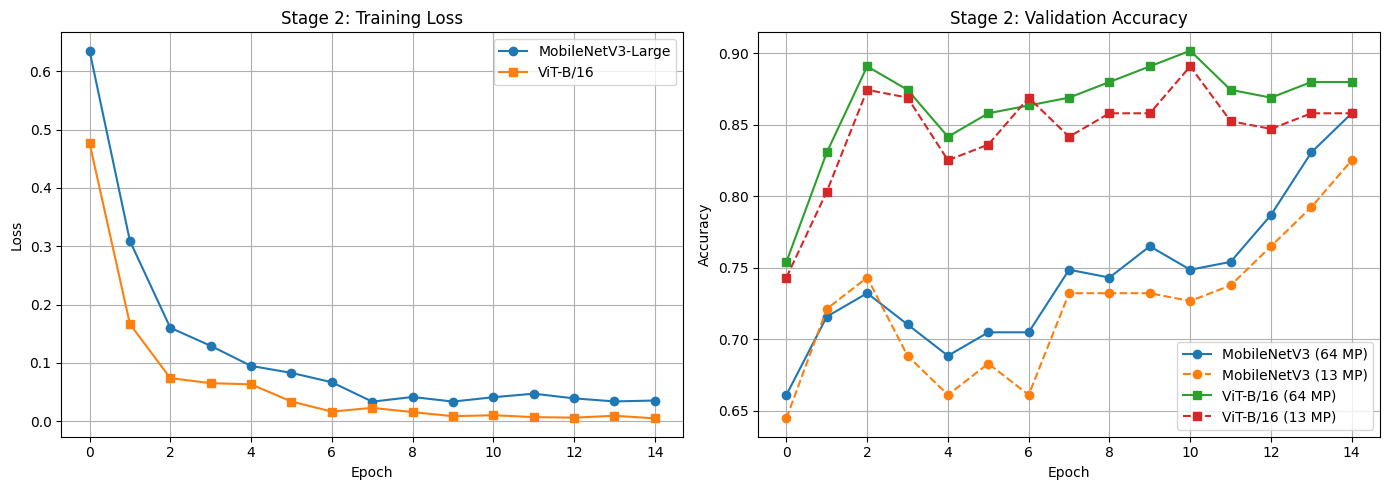

In [20]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Pembuatan Tabel Ringkasan Komparasi
summary_data = [
    {
        'Arsitektur': 'MobileNetV3-Large (64 MP)',
        'Akurasi': f"{res_mobilenet_s2['eval_64']['acc']*100:.2f}%",
        'Macro F1': f"{res_mobilenet_s2['eval_64']['f1']:.4f}",
        'Kecepatan Inferensi': f"{res_mobilenet_s2['latency_ms']:.2f} ms/biji"
    },
    {
        'Arsitektur': 'MobileNetV3-Large (13 MP)',
        'Akurasi': f"{res_mobilenet_s2['eval_13']['acc']*100:.2f}%",
        'Macro F1': f"{res_mobilenet_s2['eval_13']['f1']:.4f}",
        'Kecepatan Inferensi': f"{res_mobilenet_s2['latency_ms']:.2f} ms/biji"
    },
    {
        'Arsitektur': 'Vision Transformer (ViT-B/16) (64 MP)',
        'Akurasi': f"{res_vit_s2['eval_64']['acc']*100:.2f}%",
        'Macro F1': f"{res_vit_s2['eval_64']['f1']:.4f}",
        'Kecepatan Inferensi': f"{res_vit_s2['latency_ms']:.2f} ms/biji"
    },
    {
        'Arsitektur': 'Vision Transformer (ViT-B/16) (13 MP)',
        'Akurasi': f"{res_vit_s2['eval_13']['acc']*100:.2f}%",
        'Macro F1': f"{res_vit_s2['eval_13']['f1']:.4f}",
        'Kecepatan Inferensi': f"{res_vit_s2['latency_ms']:.2f} ms/biji"
    }
]

comparison_df = pd.DataFrame(summary_data)
print("=== PERBANDINGAN MODEL MULTI-RESOLUSI ===")
display(comparison_df)

# Simpan CSV ke Google Drive
comparison_df.to_csv(os.path.join(OUTPUT_DIR, 'multiresolution_comparison_summary.csv'), index=False)

# 2. Visualisasi Confusion Matrix
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Row 0: MobileNetV3 (64 MP vs 13 MP)
sns.heatmap(res_mobilenet_s2['eval_64']['cm'], annot=True, fmt='d', cmap='Greens', xticklabels=class_names, yticklabels=class_names, ax=axes[0,0])
axes[0,0].set_title("MobileNetV3 64 MP")

sns.heatmap(res_mobilenet_s2['eval_13']['cm'], annot=True, fmt='d', cmap='Greens', xticklabels=class_names, yticklabels=class_names, ax=axes[0,1])
axes[0,1].set_title("MobileNetV3 13 MP (Simulated)")

# Row 1: ViT (64 MP vs 13 MP)
sns.heatmap(res_vit_s2['eval_64']['cm'], annot=True, fmt='d', cmap='Purples', xticklabels=class_names, yticklabels=class_names, ax=axes[1,0])
axes[1,0].set_title("ViT-B/16 64 MP")

sns.heatmap(res_vit_s2['eval_13']['cm'], annot=True, fmt='d', cmap='Purples', xticklabels=class_names, yticklabels=class_names, ax=axes[1,1])
axes[1,1].set_title("ViT-B/16 13 MP (Simulated)")

for ax in axes.flat:
    ax.set_xlabel('Prediksi')
    ax.set_ylabel('Aktual')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'multiresolution_confusion_matrix.png'), dpi=200)
plt.show()

# 3. Plot Kurva Latihan (Training Curves Stage 2)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Loss
axes[0].plot(res_mobilenet_s2['history']['train_loss'], label='MobileNetV3-Large', marker='o')
axes[0].plot(res_vit_s2['history']['train_loss'], label='ViT-B/16', marker='s')
axes[0].set_title('Stage 2: Training Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True)

# Plot Akurasi Validasi (64 MP vs 13 MP untuk masing-masing model)
axes[1].plot(res_mobilenet_s2['history']['val_acc_64mp'], label='MobileNetV3 (64 MP)', linestyle='-', marker='o')
axes[1].plot(res_mobilenet_s2['history']['val_acc_13mp'], label='MobileNetV3 (13 MP)', linestyle='--', marker='o')
axes[1].plot(res_vit_s2['history']['val_acc_64mp'], label='ViT-B/16 (64 MP)', linestyle='-', marker='s')
axes[1].plot(res_vit_s2['history']['val_acc_13mp'], label='ViT-B/16 (13 MP)', linestyle='--', marker='s')
axes[1].set_title('Stage 2: Validation Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'stage2_learning_curves.png'), dpi=200)
plt.show()